<a href="https://colab.research.google.com/github/a01286849-glitch/damian-garza-kosikova-A01286849/blob/main/A10_Presentaciones_finales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# conect google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Import libraries
import pandas as pd
ruta = '/content/drive/MyDrive/viral_songs.csv'

# read df
df = pd.read_csv(ruta)

df.head()

,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1


# What Musical Characteristics Are Associated with Streams and Virality?

**Damián Garza Kosikova**

## Dataset Overview

- **Source:** The viral_songs.csv file provided for this analysis. The original provider and collection method are not documented.
- **Context:** The dataset contains songs, their musical characteristics, stream counts, and a virality label.
- **Observations:** 10,000 songs.
- **Variables:** 17 columns.
- **Unit of observation:** Each row represents one song.
- **Limitations:** The platform, stream measurement period, and definition of virality are not documented.

In [ ]:
# Show the number of rows and columns in the dataset.
print("Number of songs:", df.shape[0])
print("Number of original variables:", df.shape[1])

# Check for missing values.
print("Missing values:", df.isna().sum().sum())

# Check whether any song identifiers appear more than once.
print("Repeated song IDs:", df["track_id"].duplicated().sum())

Number of songs: 10000
Number of original variables: 17
Missing values: 0
Repeated song IDs: 0


## Variables of Interest

| Variable | Meaning | Type | Unit / Categories |
|---|---|---|---|
| genre | Musical genre | Categorical | 10 musical genres |
| streams | Recorded number of streams | Numerical | Stream count |
| viral | Virality label | Categorical | 0 = non-viral; 1 = viral |
| danceability | How suitable a song is for dancing | Numerical | Index from 0 to 1 |
| energy | Musical intensity | Numerical | Index from 0 to 1 |
| valence | How positive a song sounds | Numerical | Index from 0 to 1 |
| tempo_bpm | Musical speed | Numerical | Beats per minute (BPM) |

**Interpretation note:** We interpret viral = 1 as viral and viral = 0 as non-viral. The labeling criteria and musical index definitions should be confirmed with the original source.

**Time note:** This analysis compares songs. It does not study changes over time.

In [ ]:
# Select only the variables used in the eight studies.
variables = [
    "genre",
    "streams",
    "viral",
    "danceability",
    "energy",
    "valence",
    "tempo_bpm"
]

# Display the first five rows of these variables.
display(df[variables].head())

# Check the categories recorded in the dataset.
print("Musical genres:", sorted(df["genre"].unique()))
print("Virality labels:", sorted(df["viral"].unique()))

,genre,streams,viral,danceability,energy,valence,tempo_bpm
0,Pop,661412,1,0.760,0.703,0.747,140.8
1,Electronic,1114175,1,0.436,0.934,0.672,105.1
2,Hip-Hop,105832,1,0.642,0.725,0.460,90.6
3,Classical,915397,0,0.326,0.456,0.299,71.3
4,Pop,3690733,1,0.599,0.683,0.700,132.6


Musical genres: ['Classical', 'Country', 'Electronic', 'Hip-Hop', 'Indie', 'Jazz', 'Latin', 'Pop', 'R&B', 'Rock']
Virality labels: [np.int64(0), np.int64(1)]


## Analytical Roadmap

**Objective:** Explore how musical characteristics and genre are associated with streams and virality.

| Study | Research Question | Analysis / Figure | Main Insight |
|---|---|---|---|
| 1 | How are streams distributed, and how do the mean and median compare? | Histogram with mean and median | Pending analysis |
| 2 | Which genres have the highest median streams per song? | Horizontal bar chart of median streams | Pending analysis |
| 3 | How does the percentage of viral songs differ across genres? | Bar chart of viral percentages | Pending analysis |
| 4 | How does danceability differ between viral and non-viral songs? | Box plot by virality label | Pending analysis |
| 5 | What relationship exists between energy and streams? | Scatter plot and correlation | Pending analysis |
| 6 | How does the percentage of viral songs differ across tempo groups? | Bar chart by tempo group | Pending analysis |
| 7 | How are danceability, energy, and valence related to each other? | Correlation heatmap | Pending analysis |
| 8 | How are danceability, energy, and valence jointly associated with streams? | Multiple linear regression and observed-versus-predicted plot | Pending analysis |

## Study 1: Distribution of Streams

**Research question:** How are streams distributed, and how do the mean and median compare?

**Analysis:** Calculate the mean and median and use a histogram to examine the distribution.

**Why this figure?** A histogram shows how many songs fall within each range of stream counts.

Mean streams: 2,415,685
Median streams: 329,058


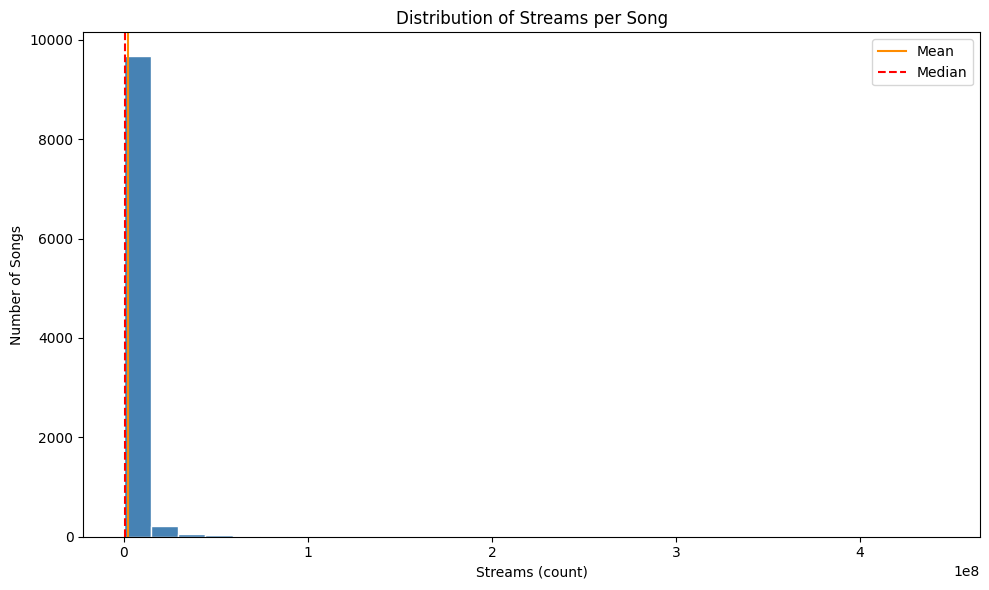

In [ ]:
# Import the tool used to create graphs.
import matplotlib.pyplot as plt

# Calculate the average number of streams.
mean_streams = df["streams"].mean()

# Calculate the middle value of the stream counts.
median_streams = df["streams"].median()

# Display the results.
print(f"Mean streams: {mean_streams:,.0f}")
print(f"Median streams: {median_streams:,.0f}")

# Create a figure large enough for the presentation.
plt.figure(figsize=(10, 6))

# Group stream counts into 30 intervals and count songs in each interval.
plt.hist(df["streams"], bins=30, color="steelblue", edgecolor="white")

# Add vertical lines to identify the mean and median.
plt.axvline(mean_streams, color="darkorange", label="Mean")
plt.axvline(median_streams, color="red", linestyle="--", label="Median")

# Add a title, axis labels, and a legend.
plt.title("Distribution of Streams per Song")
plt.xlabel("Streams (count)")
plt.ylabel("Number of Songs")
plt.legend()

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

### Key Insights

1. Mean streams are approximately 2.42 million, while median streams are 329,058.
2. The much higher mean indicates a right-skewed distribution: songs with very high stream counts pull the average upward.

## Study 2: Median Streams by Genre

**Research question:** Which genres have the highest median streams per song?

**Analysis:** Group songs by genre and compare their median stream counts.

**Why this figure?** A horizontal bar chart makes genre rankings easy to compare. The median reduces the influence of songs with extremely high stream counts.

Median streams by genre:
genre
Jazz          150482.0
Classical     159661.0
Indie         192274.0
Country       226331.5
Rock          274696.5
R&B           339723.5
Electronic    539456.0
Pop           660266.0
Hip-Hop       779180.5
Latin         895084.0
Name: streams, dtype: float64


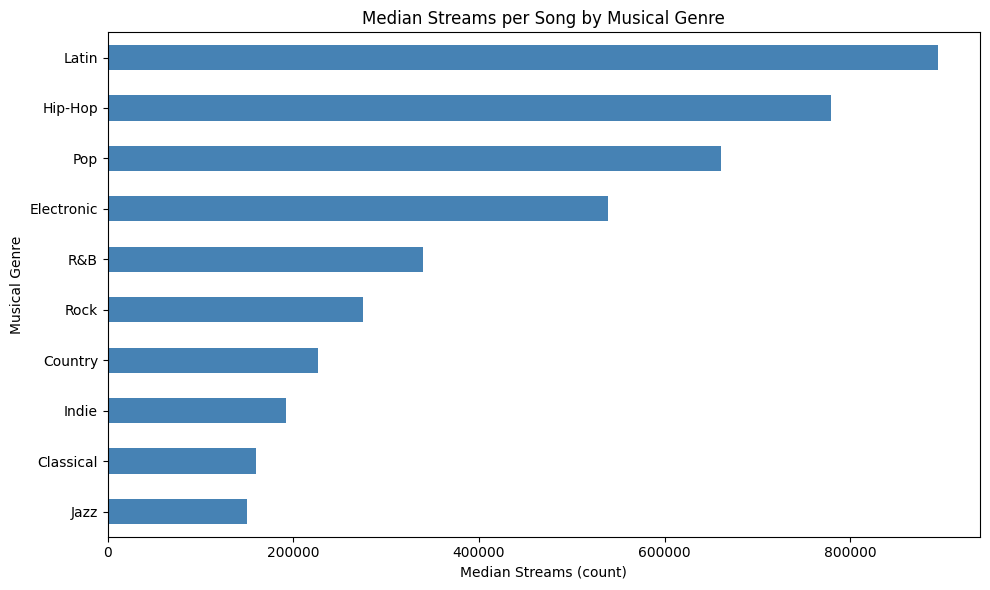

In [ ]:
# Group songs by genre and calculate median streams for each genre.
genre_medians = df.groupby("genre")["streams"].median()

# Sort the results from lowest to highest.
genre_medians = genre_medians.sort_values()

# Display the exact values used in the graph.
print("Median streams by genre:")
print(genre_medians)

# Create a horizontal bar chart.
genre_medians.plot(
    kind="barh",
    figsize=(10, 6),
    color="steelblue"
)

# Add a meaningful title and axis labels.
plt.title("Median Streams per Song by Musical Genre")
plt.xlabel("Median Streams (count)")
plt.ylabel("Musical Genre")

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

### Key Insights

1. Latin has the highest median stream count at 895,084, followed by Hip-Hop at approximately 779,181.
2. Jazz has the lowest median at 150,482, showing substantial differences across genres in this dataset.

## Study 3: Percentage of Viral Songs by Genre

**Research question:** How does the percentage of viral songs differ across genres?

**Analysis:** Calculate the percentage of songs labeled as viral within each genre.

**Why this figure?** A bar chart makes percentages easy to compare. Percentages account for differences in the number of songs per genre.

**Interpretation:** We treat viral = 1 as viral and viral = 0 as non-viral. The original labeling criteria are not documented.

,total_songs,viral_songs,viral_percentage
genre,,,
Classical,991,12,1.21
Jazz,965,61,6.32
Indie,993,138,13.90
Country,942,225,23.89
Rock,1084,354,32.66
R&B,950,385,40.53
Electronic,991,502,50.66
Hip-Hop,1052,643,61.12
Pop,1002,619,61.78


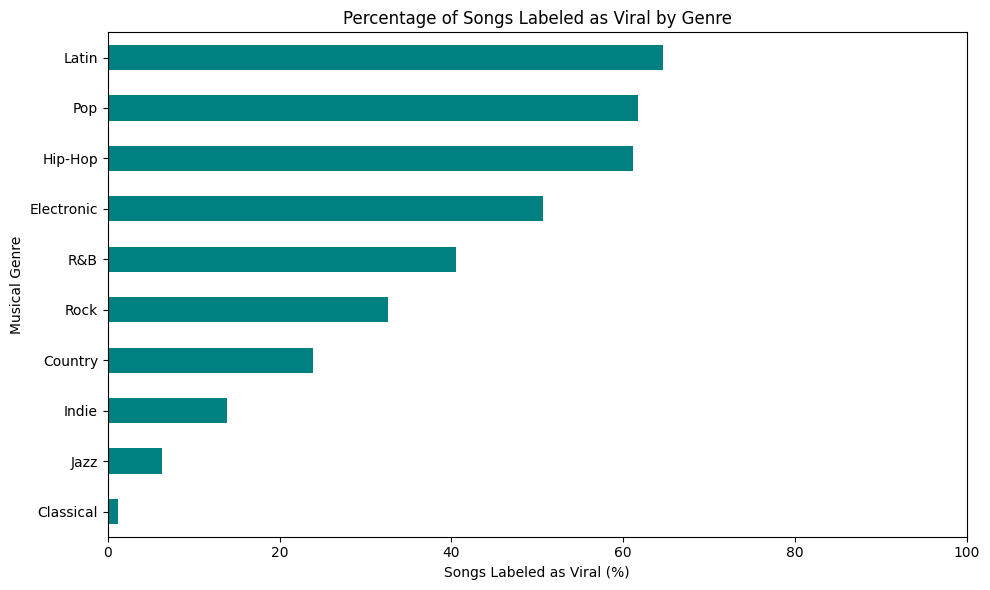

In [ ]:
# Count all songs and songs labeled as viral within each genre.
genre_summary = df.groupby("genre")["viral"].agg(["count", "sum"])

# Rename the columns to make the table easier to understand.
genre_summary.columns = ["total_songs", "viral_songs"]

# Divide viral songs by total songs and multiply by 100.
genre_summary["viral_percentage"] = (
    genre_summary["viral_songs"] / genre_summary["total_songs"] * 100
)

# Sort genres from lowest to highest percentage.
genre_summary = genre_summary.sort_values("viral_percentage")

# Display the counts and percentages behind the graph.
display(genre_summary.round(2))

# Create a horizontal bar chart.
genre_summary["viral_percentage"].plot(
    kind="barh",
    figsize=(10, 6),
    color="teal"
)

# Add the title, axis labels, and percentage scale.
plt.title("Percentage of Songs Labeled as Viral by Genre")
plt.xlabel("Songs Labeled as Viral (%)")
plt.ylabel("Musical Genre")
plt.xlim(0, 100)

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

### Key Insights

1. Latin has the highest percentage of songs labeled as viral (64.66%), followed by Pop (61.78%) and Hip-Hop (61.12%).
2. Classical has the lowest percentage (1.21%), showing large differences in viral labeling across genres in this dataset.

## Study 4: Danceability and Virality

**Research question:** How does danceability differ between viral and non-viral songs?

**Analysis:** Compare the distribution and median danceability of the two groups.

**Why this figure?** A box plot compares the middle values, spread, and overlap of both distributions.

,count,median
viral,,
0,6395,0.559
1,3605,0.720


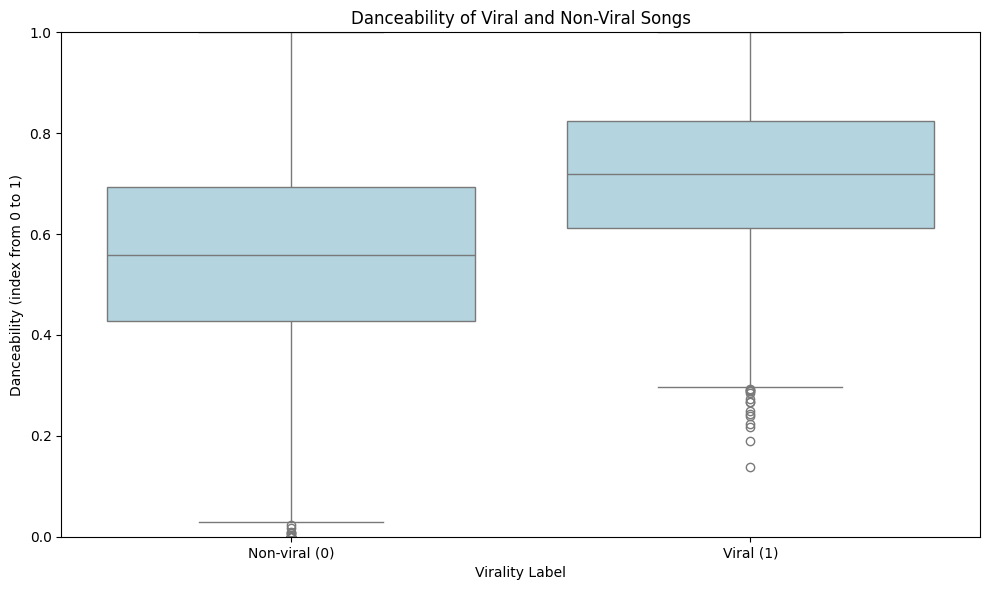

In [ ]:
# Import seaborn to create a box plot.
import seaborn as sns

# Display the number of songs and median danceability in each group.
dance_summary = df.groupby("viral")["danceability"].agg(
    ["count", "median"]
)
display(dance_summary)

# Create a box plot comparing the two groups.
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x="viral",
    y="danceability",
    color="lightblue"
)

# Replace numeric labels with descriptive group names.
plt.xticks([0, 1], ["Non-viral (0)", "Viral (1)"])

# Add the title, axis labels, and index scale.
plt.title("Danceability of Viral and Non-Viral Songs")
plt.xlabel("Virality Label")
plt.ylabel("Danceability (index from 0 to 1)")
plt.ylim(0, 1)

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

### Key Insights

1. Songs labeled as viral have higher median danceability (0.720) than non-viral songs (0.559).
2. The difference in medians is 0.161 index units. This is an association and does not prove that higher danceability causes virality.

## Study 5: Energy and Streams

**Research question:** What relationship exists between energy and streams?

**Analysis:** Calculate Pearson's correlation and examine a scatter plot.

**Why this figure?** A scatter plot shows the relationship between two numerical variables. Each point represents one song.

Correlation between energy and streams: 0.074


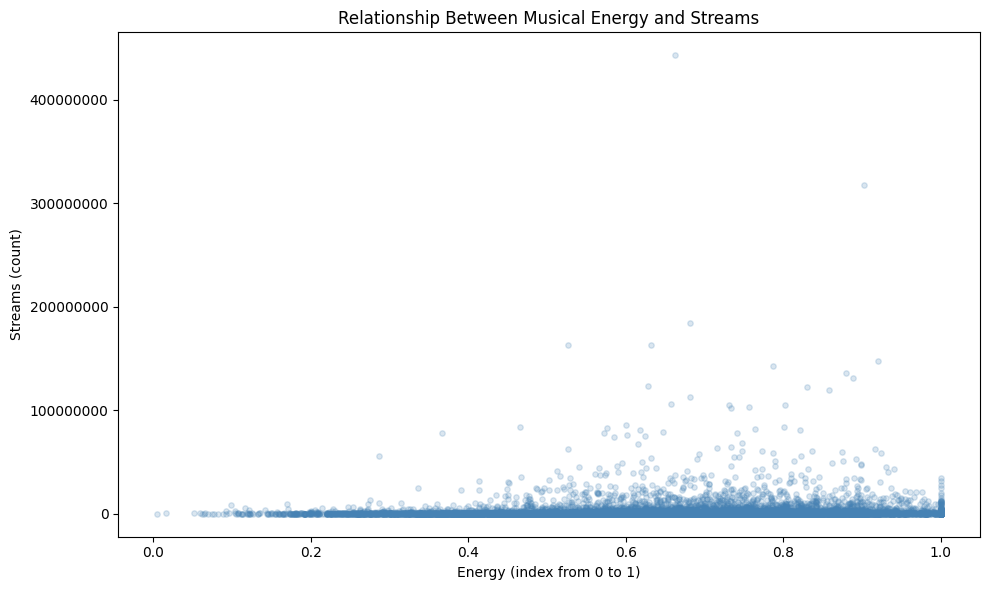

In [ ]:
# Calculate the linear correlation between energy and streams.
energy_correlation = df["energy"].corr(df["streams"])

# Display the correlation rounded to three decimal places.
print(f"Correlation between energy and streams: {energy_correlation:.3f}")

# Create a scatter plot where each point represents one song.
plt.figure(figsize=(10, 6))
plt.scatter(
    df["energy"],
    df["streams"],
    color="steelblue",
    alpha=0.2,
    s=15
)

# Add a title and axis labels.
plt.title("Relationship Between Musical Energy and Streams")
plt.xlabel("Energy (index from 0 to 1)")
plt.ylabel("Streams (count)")

# Display stream counts without scientific notation.
plt.ticklabel_format(style="plain", axis="y")

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

### Key Insights

1. Energy and streams have a very weak positive linear correlation (r = 0.074).
2. Energy alone provides little information about stream counts through a linear relationship in this dataset.

## Study 6: Tempo Groups and Virality

**Research question:** How does the percentage of viral songs differ across tempo groups?

**Analysis:** Divide songs into three tempo groups and calculate the viral percentage within each group.

- **Low:** Up to 100 BPM.
- **Medium:** Above 100 and up to 140 BPM.
- **High:** Above 140 BPM.

These boundaries were selected for this exploration; they are not official musical categories.

**Why this figure?** A bar chart makes the viral percentages of the three groups easy to compare.

,total_songs,viral_songs,viral_percentage
tempo_group,,,
Low,2866,1014,35.38
Medium,6520,2339,35.87
High,614,252,41.04


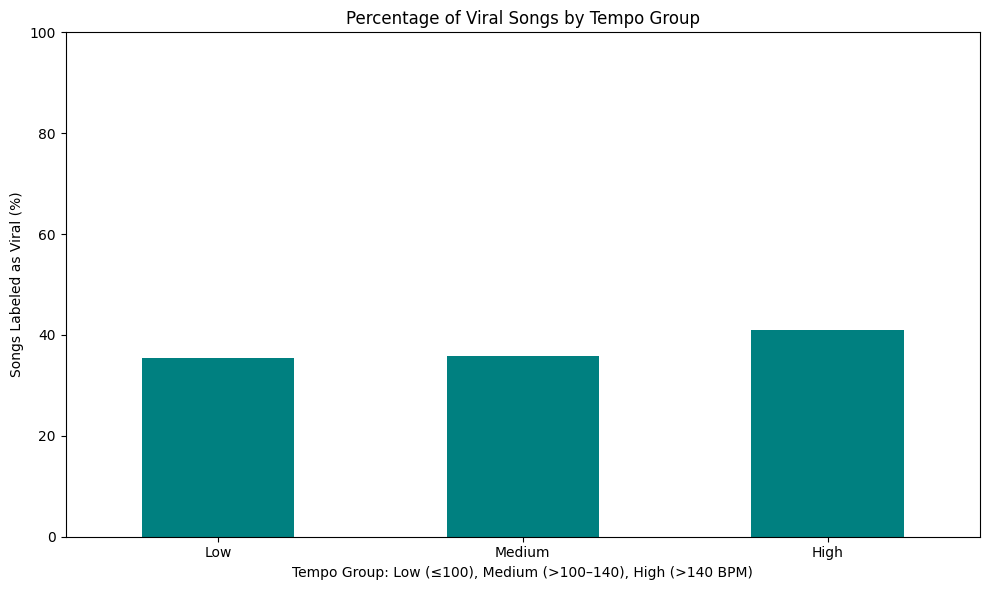

In [11]:
# Group tempo values into three intervals measured in beats per minute.
df["tempo_group"] = pd.cut(
    df["tempo_bpm"],
    bins=[0, 100, 140, float("inf")],
    labels=["Low", "Medium", "High"]
)

# Count all songs and songs labeled as viral in each tempo group.
tempo_summary = df.groupby(
    "tempo_group", observed=True
)["viral"].agg(["count", "sum"])

# Rename the columns to make the results easier to understand.
tempo_summary.columns = ["total_songs", "viral_songs"]

# Calculate the percentage of viral songs within each group.
tempo_summary["viral_percentage"] = (
    tempo_summary["viral_songs"] / tempo_summary["total_songs"] * 100
)

# Display the counts and percentages used in the graph.
display(tempo_summary.round(2))

# Create a bar chart comparing the three percentages.
tempo_summary["viral_percentage"].plot(
    kind="bar",
    figsize=(10, 6),
    color="teal",
    rot=0
)

# Add the title, labels, and percentage scale.
plt.title("Percentage of Viral Songs by Tempo Group")
plt.xlabel("Tempo Group: Low (≤100), Medium (>100–140), High (>140 BPM)")
plt.ylabel("Songs Labeled as Viral (%)")
plt.ylim(0, 100)

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

### Key Insights

1. The high-tempo group has the highest viral percentage (41.04%), compared with 35.87% for medium tempo and 35.38% for low tempo.
2. The high-tempo group contains only 614 songs, compared with 6,520 in the medium group. These descriptive differences do not establish statistical significance or causation.

## Study 7: Relationships Between Musical Characteristics

**Research question:** How are danceability, energy, and valence related to each other?

**Analysis:** Calculate Pearson's correlations between the three musical characteristics.

**Why this figure?** A correlation heatmap summarizes several numerical relationships in one figure.

These characteristics will also be used as explanatory variables in Study 8.

,danceability,energy,valence
danceability,1.000,0.405,0.235
energy,0.405,1.000,0.143
valence,0.235,0.143,1.000


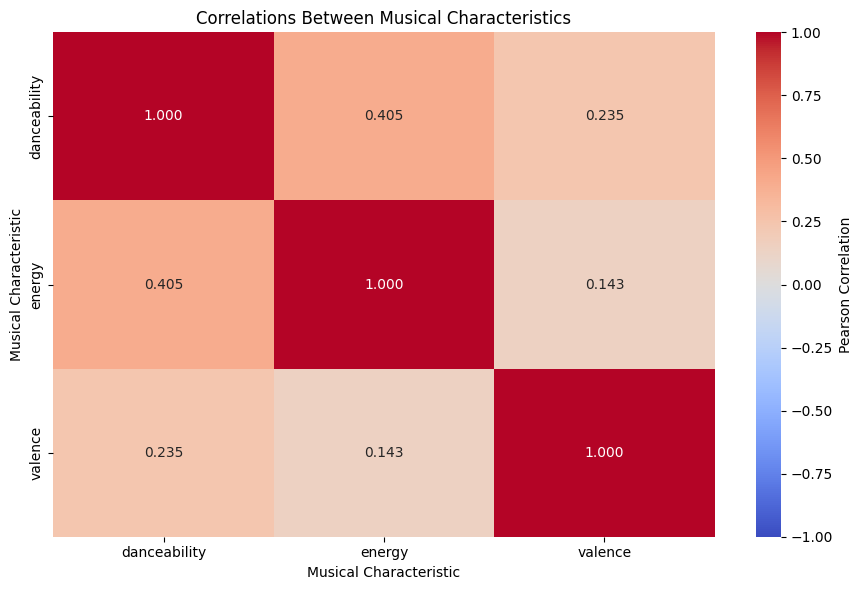

In [12]:
# Select the three musical characteristics.
music_features = df[["danceability", "energy", "valence"]]

# Calculate the correlation between each pair of variables.
correlation_matrix = music_features.corr()

# Display the exact correlations rounded to three decimal places.
display(correlation_matrix.round(3))

# Create a heatmap showing the correlations.
plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    cbar_kws={"label": "Pearson Correlation"}
)

# Add a title and axis labels.
plt.title("Correlations Between Musical Characteristics")
plt.xlabel("Musical Characteristic")
plt.ylabel("Musical Characteristic")

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

### Key Insights

1. Danceability and energy have the strongest positive correlation among the three pairs (r = 0.405).
2. Valence has weaker positive correlations with danceability (r = 0.235) and energy (r = 0.143).

## Study 8: Explaining Streams with Multiple Linear Regression

**Research question:** How are danceability, energy, and valence jointly associated with streams?

**Dependent variable (Y):** streams.

**Independent variables (X):** danceability, energy, and valence.

**Model:**

Estimated streams = intercept + b_danceability × danceability + b_energy × energy + b_valence × valence

**Purpose:** Explore how the three characteristics are associated with streams when considered together.

In [14]:
# Import the tool used to fit a linear regression.
from sklearn.linear_model import LinearRegression

# Select the three explanatory variables.
X = df[["danceability", "energy", "valence"]]

# Select the outcome variable.
y = df["streams"]

# Create the regression model.
model = LinearRegression()

# Estimate the intercept and coefficients using the dataset.
model.fit(X, y)

print("The regression model is ready.")

The regression model is ready.


In [15]:
# Create a table with the estimated coefficients.
coefficients = pd.DataFrame({
    "Variable": X.columns,
    "Coefficient": model.coef_
})

# Display the coefficients and intercept.
display(coefficients.round(2))
print(f"Intercept: {model.intercept_:,.2f}")

# Calculate the proportion of variation explained within this dataset.
r_squared = model.score(X, y)

print(f"R-squared: {r_squared:.4f}")
print(f"Variation explained: {r_squared * 100:.2f}%")

# Display the fitted equation.
print("\nEstimated streams =")
print(f"{model.intercept_:.2f}")
print(f"+ ({model.coef_[0]:.2f} × danceability)")
print(f"+ ({model.coef_[1]:.2f} × energy)")
print(f"+ ({model.coef_[2]:.2f} × valence)")

,Variable,Coefficient
0,danceability,5253672.70
1,energy,1467948.95
2,valence,1324229.29


Intercept: -2,526,118.67
R-squared: 0.0160
Variation explained: 1.60%

Estimated streams =
-2526118.67
+ (5253672.70 × danceability)
+ (1467948.95 × energy)
+ (1324229.29 × valence)


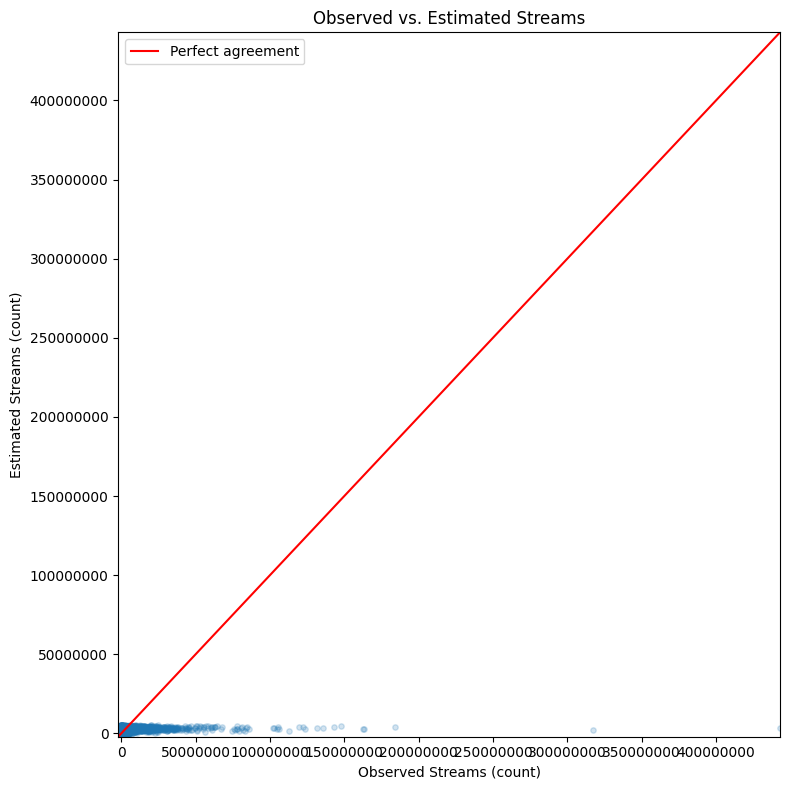

In [16]:
# Calculate estimated streams for the songs used to fit the model.
predicted_streams = model.predict(X)

# Set the same limits for both axes.
lower_limit = min(y.min(), predicted_streams.min())
upper_limit = max(y.max(), predicted_streams.max())

# Plot observed streams against estimated streams.
plt.figure(figsize=(8, 8))
plt.scatter(y, predicted_streams, alpha=0.2, s=15)

# Add a reference line showing perfect agreement.
plt.plot(
    [lower_limit, upper_limit],
    [lower_limit, upper_limit],
    color="red",
    label="Perfect agreement"
)

# Add matching scales, a title, and axis labels.
plt.xlim(lower_limit, upper_limit)
plt.ylim(lower_limit, upper_limit)
plt.title("Observed vs. Estimated Streams")
plt.xlabel("Observed Streams (count)")
plt.ylabel("Estimated Streams (count)")
plt.ticklabel_format(style="plain", axis="both")
plt.legend()

# Adjust spacing and display the graph.
plt.tight_layout()
plt.show()

### Estimated Equation

Estimated streams = −2,526,118.67 + 5,253,672.70 × danceability + 1,467,948.95 × energy + 1,324,229.29 × valence

### Key Insights

1. All three estimated coefficients are positive. Holding the other characteristics constant, a 0.1-unit increase in danceability is associated with approximately 525,367 additional estimated streams.
2. R² = 0.016: the model explains only 1.60% of the variation in streams within this dataset. These characteristics provide limited explanatory power.

### Model Limitations

This is a descriptive model fitted and evaluated on the same dataset. Its performance on new songs has not been tested. The coefficients do not establish causation.

Linear regression can produce negative stream estimates, which are not realistic counts. This further limits its use for prediction.

## Final Conclusions

1. Stream counts are unevenly distributed. The mean is approximately 2.42 million, while the median is 329,058, showing the influence of songs with very high stream counts.

2. Latin has both the highest median streams and the highest viral percentage in this dataset. However, rankings differ: Hip-Hop ranks second in median streams, while Pop ranks second in viral percentage.

3. Viral songs have higher median danceability. High-tempo songs also have a higher viral percentage, although their group is smaller. These associations do not demonstrate causation.

4. Energy has a very weak linear relationship with streams. Although danceability and energy are positively correlated, the regression using danceability, energy, and valence explains only 1.60% of stream variation.

### Practical Implication

Musical characteristics alone provide limited information about stream counts. Before making decisions, this analysis should be complemented with information about promotion, audience, playlist exposure, and platform.

### Limitations

- The original source, sampling method, and possible synthetic nature of the dataset are unconfirmed.
- The platform, stream measurement period, and viral labeling criteria are not documented.
- Group differences are descriptive; statistical significance was not tested.
- The regression was evaluated on the same data used to fit it.
- Findings apply to this dataset and do not establish causal relationships.